# Quanto interesse vai haver nas próximas semanas, e quanto dá para confiar na previsão?

Quem planeja verba e estoque para Black Friday, Dia das Mães ou Natal precisa de duas coisas: uma previsão e uma
faixa de erro honesta em volta dela. Este notebook testa as duas em dez séries públicas de interesse: as
visualizações semanais de artigos da Wikipédia em português sobre datas e temas de consumo.

**Visualização de artigo é um indicador de interesse, não de venda.** A série serve para testar o método numa base
pública, longa e fortemente sazonal.

O roteiro:

1. os dados;
2. a previsão pontual: dois modelos contra duas linhas de base, validados por origem móvel;
3. os intervalos de previsão no geral: o que cada método promete e o que entrega;
4. os intervalos na semana que importa, a da data comemorativa;
5. quando os erros mudam de tamanho: o que o intervalo adaptativo compra;
6. o intervalo conformal em volta de cada previsor.

Toda tabela sai de uma função de `src/previsao_demanda/analise.py`; os mesmos números estão em
`reports/resultados.json`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from previsao_demanda import analise, dados, graficos, previsores

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.3f}".replace(".", ","))
pd.set_option("display.max_columns", 30)

## 1. Os dados

Dez artigos, 590 semanas completas (de segunda a domingo), de julho de 2015 a outubro de 2026. Fonte: API pública
de visualizações da Wikimedia (licença CC0). O extrato semanal está versionado em `data/`; o script
`scripts/baixar_dados.py` o regenera.

In [2]:
semanal = dados.carregar_semanal()
resumo = pd.DataFrame({
    "mediana semanal": semanal.median(),
    "maior semana": semanal.max(),
    "pico ÷ mediana": semanal.max() / semanal.median(),
    "semana do maior pico": semanal.idxmax().dt.strftime("%d/%m/%Y"),
}).rename(index=dados.rotulo)
total = f"{int(semanal.to_numpy().sum()):,}".replace(",", ".")
print(f"{semanal.shape[0]} semanas, de {semanal.index[0]:%d/%m/%Y} a {semanal.index[-1]:%d/%m/%Y}; {total} visualizações")
resumo.style.format({"mediana semanal": "{:.0f}", "maior semana": "{:.0f}", "pico ÷ mediana": "{:.0f}"})

590 semanas, de 06/07/2015 a 19/10/2026; 20.863.288 visualizações


,mediana semanal,maior semana,pico ÷ mediana,semana do maior pico
Black Friday,482,97416,202,25/11/2019
Dia das Mães,624,108910,175,08/05/2023
Dia dos Pais,592,72693,123,08/08/2022
Dia dos Namorados,1648,233303,142,13/02/2017
Natal,1182,77519,66,19/12/2016
Páscoa,1310,182949,140,10/04/2017
Carnaval,2274,148201,65,27/02/2017
Festa junina,734,95510,130,13/06/2016
Imposto de renda,1033,6991,7,25/04/2016
Enem,1088,84758,78,29/10/2018


São séries de pico: a semana mais alta chega a ser mais de cem vezes a semana típica. Por isso os modelos trabalham
em `log(1 + y)` e os intervalos são multiplicativos ("de metade ao dobro da previsão").

Um detalhe que só aparece olhando: o artigo "Dia dos Namorados" tem o maior pico em fevereiro (São Valentim, 14/02),
não em junho. A Wikipédia em português é lida também em Portugal.

## 2. A previsão pontual

**Desenho da validação (origem móvel).** A origem é a semana em que a previsão é feita. Em cada origem o modelo vê
só o passado, prevê as 8 semanas seguintes e é cobrado pelo que aconteceu; a origem anda uma semana e tudo se repete.

- primeira origem com 3 anos de história (156 semanas);
- as 104 primeiras origens são de **aquecimento**: servem só para juntar erros que calibram os intervalos e não
  entram em nenhuma métrica;
- as métricas usam as 323 origens seguintes (de junho de 2020 a agosto de 2026);
- os modelos são reestimados a cada 13 semanas, só com o passado.

**Previsores.** Linhas de base: a sazonal ingênua (a mesma semana do ano anterior) e a média móvel de 4 semanas.
Modelos: suavização exponencial com sazonalidade (ETS do `statsmodels`) e gradient boosting (LightGBM) com
defasagens e calendário, incluindo a distância até cada data comemorativa, calculada no código.

A célula abaixo roda a análise inteira (cerca de dois minutos).

In [3]:
r = analise.rodar(semanal)
pd.Series(r.base)

artigos                                    10
semanas                                   590
primeira_semana                    2015-07-06
ultima_semana                      2026-10-19
visualizacoes_no_periodo             20863288
origens_no_backtest                       427
origens_de_aquecimento                    104
origens_avaliadas                         323
primeira_origem_avaliada           2020-06-29
ultima_origem_avaliada             2026-08-31
previsoes_avaliadas_por_modelo          25840
horizonte_max                               8
bloco_do_bootstrap                         13
repeticoes_do_bootstrap                  2000
reajuste_dos_modelos_em_semanas            13
dtype: object

In [4]:
comparacao = r.comparacao.set_index("nome")[["mase", "mase_inf", "mase_sup", "wape", "razao_para_a_sazonal", "razao_inf", "razao_sup", "veredito"]]
comparacao

,mase,mase_inf,mase_sup,wape,razao_para_a_sazonal,razao_inf,razao_sup,veredito
nome,,,,,,,,
Sazonal ingênua,"0,728","0,609","0,889","0,647","1,000","1,000","1,000",linha de base
Média móvel,"1,596","1,338","1,889","1,253","2,193","1,892","2,439",erra mais
Suavização exponencial,"0,625","0,532","0,756","0,542","0,859","0,783","0,948",erra menos
Gradient boosting,"0,502","0,404","0,629","0,433","0,690","0,614","0,753",erra menos


**Como ler.** MASE é o erro absoluto dividido pelo erro histórico da sazonal ingênua, com cada artigo pesando igual.
WAPE é a soma dos erros sobre a soma do realizado, então pesa pelo volume. A razão compara cada previsor com a
sazonal ingênua nas mesmas origens; o intervalo vem de um bootstrap em blocos de 13 origens, porque erros de origens
vizinhas são correlacionados. Intervalo inteiro abaixo de 1: erra menos. Intervalo que contém 1: empate.

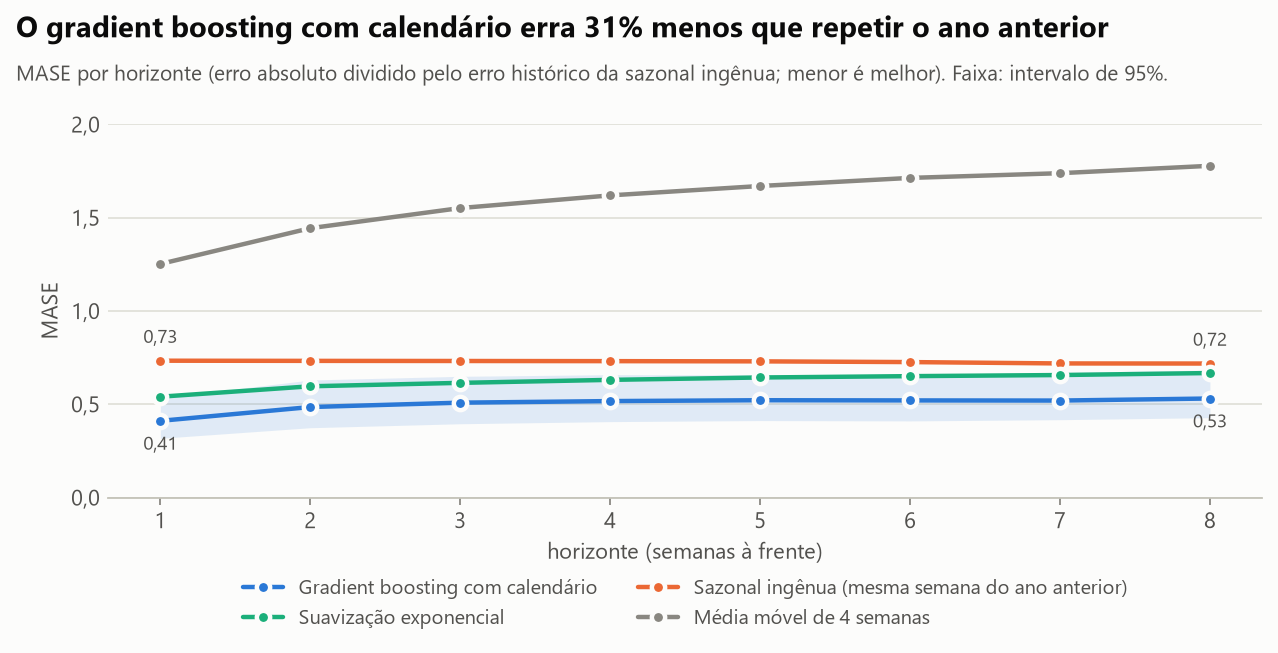

horizonte,1,2,3,4,5,6,7,8
modelo,,,,,,,,
Suavização exponencial,"0,541","0,596","0,615","0,631","0,644","0,651","0,657","0,668"
Gradient boosting,"0,411","0,485","0,509","0,517","0,522","0,521","0,520","0,531"
Média móvel,"1,252","1,444","1,552","1,620","1,670","1,713","1,739","1,778"
Sazonal ingênua,"0,734","0,733","0,732","0,731","0,730","0,726","0,719","0,718"


In [5]:
fig = graficos.erro_por_horizonte(r.erro_por_horizonte, r.comparacao)
display(fig); plt.close(fig)
r.erro_por_horizonte["mase"].unstack("horizonte").rename(index=analise.MODELOS)

In [6]:
pd.concat({"gradient boosting ÷ sazonal": r.razao_por_horizonte["gbm"], "suavização exponencial ÷ sazonal": r.razao_por_horizonte["ets"]}, axis=1)

gradient boosting ÷ sazonal                      \
                                razao razao_inf razao_sup   
horizonte                                                   
1                               0,561     0,483     0,629   
2                               0,662     0,570     0,737   
3                               0,695     0,600     0,769   
4                               0,707     0,622     0,781   
5                               0,715     0,630     0,784   
6                               0,717     0,636     0,784   
7                               0,723     0,638     0,803   
8                               0,739     0,656     0,820   

          suavização exponencial ÷ sazonal                      
                                     razao razao_inf razao_sup  
horizonte                                                       
1                                    0,737     0,653     0,829  
2                                    0,814     0,732     0,912  
3                                    0,840     0,756     0,941  
4                                    0,863     0,783     0,960  
5                                    0,882     0,798     0,983  
6                                    0,896     0,802     1,013  
7                                    0,913     0,819     1,030  
8                                    0,929     0,837     1,041

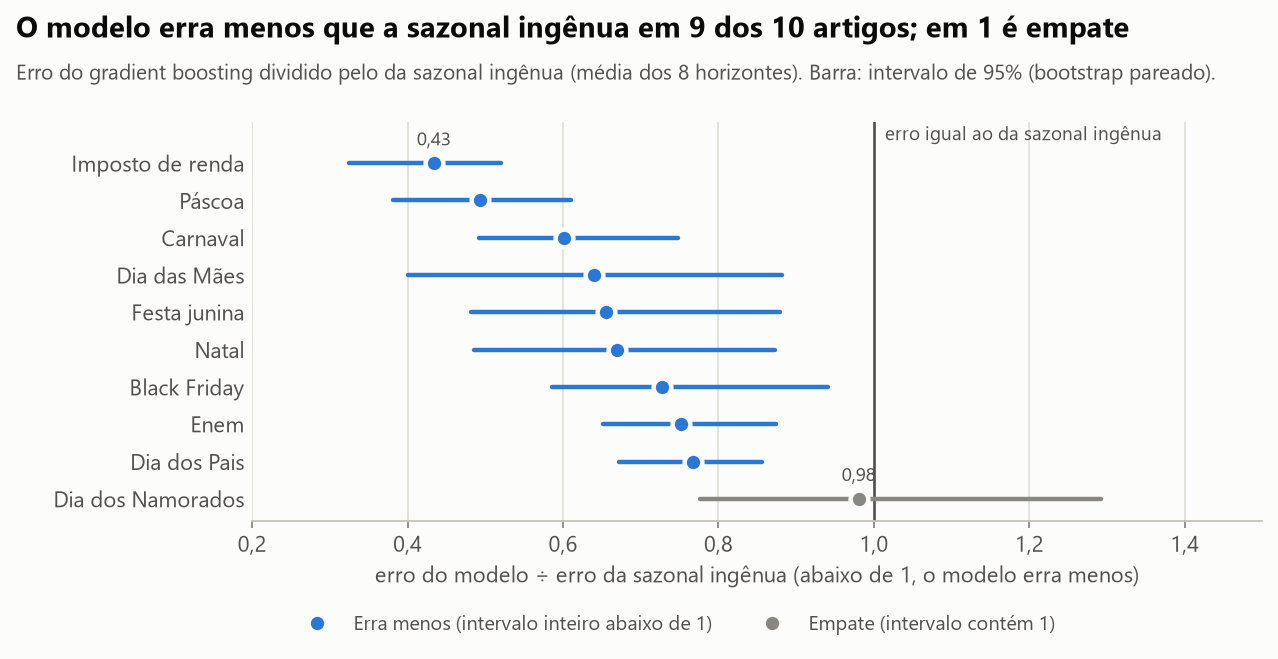

,mase_sazonal,mase_ets,mase_gbm,razao_gbm,razao_gbm_inf,razao_gbm_sup
artigo,,,,,,
Imposto de renda,"0,551","0,250","0,239","0,434","0,324","0,521"
Páscoa,"0,478","0,320","0,236","0,493","0,381","0,610"
Carnaval,"0,404","0,281","0,243","0,601","0,492","0,748"
Dia das Mães,"1,422","0,927","0,910","0,640","0,400","0,882"
Festa junina,"0,274","0,405","0,180","0,656","0,482","0,879"
Natal,"0,872","0,916","0,584","0,670","0,486","0,873"
Black Friday,"0,457","0,492","0,333","0,728","0,586","0,941"
Enem,"0,334","0,336","0,251","0,751","0,651","0,875"
Dia dos Pais,"1,839","1,563","1,410","0,767","0,671","0,856"


In [7]:
fig = graficos.erro_por_artigo(r.erro_por_artigo)
display(fig); plt.close(fig)
r.erro_por_artigo[["mase_sazonal", "mase_ets", "mase_gbm", "razao_gbm", "razao_gbm_inf", "razao_gbm_sup"]].sort_values("razao_gbm")

A média móvel não serve para série sazonal: ela chega atrasada em todo pico. A sazonal ingênua é uma linha de base
séria, e mesmo assim o gradient boosting erra menos, em todos os horizontes. Por artigo, a tabela acima mostra onde o
ganho é claro e onde é empate.

O WAPE continua alto em qualquer previsor. Séries de pico são difíceis, e isso leva à segunda metade da pergunta:
quanto confiar.

**Uma decisão tomada no meio do caminho.** O tamanho mínimo de folha do gradient boosting começou em 20. Um teste
sintético mostrou que, com folhas desse tamanho, o modelo não isola uma data que acontece uma vez por ano, e o valor
foi reduzido para 5 olhando só as origens de aquecimento. A célula abaixo mostra o que o desenho inicial teria dado
na janela de avaliação: a conclusão não depende dessa escolha.

In [8]:
pd.Series(r.sensibilidade_a_folha)

folha_do_estudo                             5,000
folha_inicial                              20,000
mase_com_a_folha_inicial                    0,505
razao_para_a_sazonal_com_a_folha_inicial    0,694
razao_inf                                   0,622
razao_sup                                   0,754
dtype: float64

## 3. Os intervalos de previsão, no geral

Três jeitos de pôr uma faixa em volta da mesma previsão (a da suavização exponencial, que é o modelo que declara um
intervalo próprio):

- **paramétrico do modelo:** supõe erro normal com a variância que o modelo estimou;
- **conformal simples:** o raio é o quantil dos erros que o modelo cometeu de verdade em previsões passadas, fora
  da amostra;
- **conformal adaptativo (ACI):** o mesmo quantil, com o nível corrigido a cada erro observado.

Os dois conformes foram implementados em NumPy (`src/previsao_demanda/conformal.py`) e testados contra dados
sintéticos de distribuição conhecida. Com horizonte h, o erro de uma previsão só é conhecido h semanas depois; a
calibração respeita esse atraso.

Cobertura real é a fração das previsões em que o valor ficou dentro da faixa. `fator_mediano` é a largura típica: a
faixa vai de previsão ÷ fator a previsão × fator.

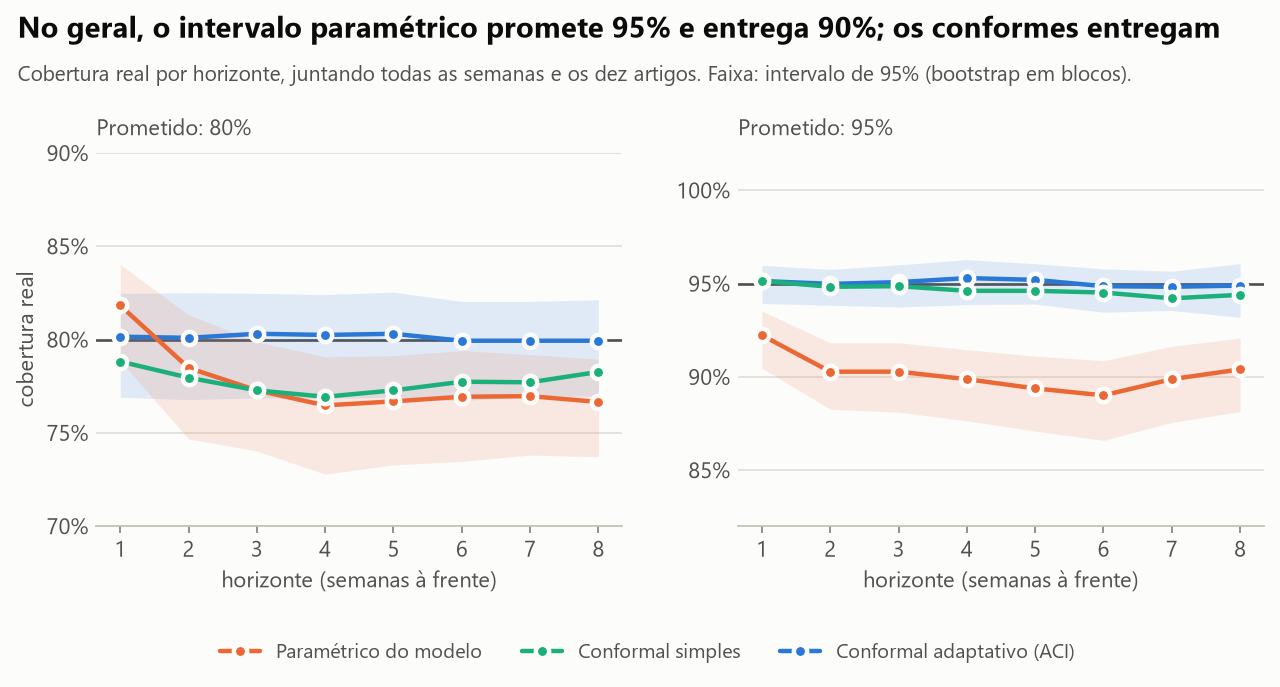

,,cobertura,cobertura_inf,cobertura_sup,fator_mediano,intervalos_infinitos
metodo,nivel,,,,,
Paramétrico do modelo,"0,800","0,777","0,746","0,800","1,654","0,000"
Conformal simples,"0,800","0,777","0,745","0,802","1,663","0,000"
Conformal adaptativo (ACI),"0,800","0,801","0,771","0,822","1,732","0,009"
Conformal por grupo,"0,800","0,776","0,743","0,801","1,634","0,000"
Paramétrico do modelo,"0,950","0,902","0,881","0,917","2,159","0,000"
Conformal simples,"0,950","0,946","0,932","0,957","2,774","0,000"
Conformal adaptativo (ACI),"0,950","0,950","0,939","0,958","3,206","0,130"
Conformal por grupo,"0,950","0,947","0,932","0,958","2,672","0,000"


In [9]:
fig = graficos.cobertura_por_horizonte(r.cobertura)
display(fig); plt.close(fig)
r.cobertura.xs(0, level="horizonte").rename(index=analise.METODOS, level="metodo")

No nível de 95% o paramétrico promete mais do que entrega; os conformes ficam no prometido. No de 80% os três ficam
próximos. O preço do adaptativo a 95% está na última coluna: uma parte dos intervalos é infinita, isto é, o método
responde "não sei" naquela semana.

(A quarta linha, "conformal por grupo", é explicada na próxima seção.)

## 4. Os intervalos na semana que importa

A garantia dos métodos conformes vale **na média de todas as semanas**. Quem planeja verba não olha a média: olha a
semana da data comemorativa. A tabela abaixo separa as previsões cujo alvo é a semana da data do artigo ou a
anterior (definição fixada antes de olhar o resultado) das demais. Imposto de renda e Enem ficam fora desse recorte,
porque a data deles muda por lei ou edital e não dá para calcular.

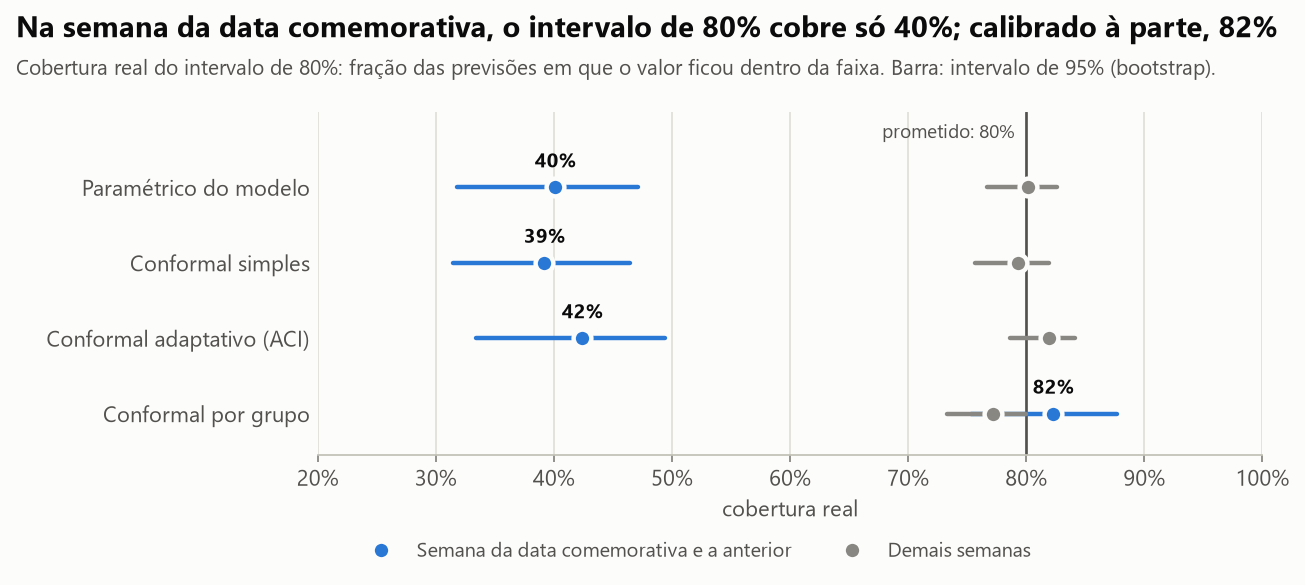

previsoes  cobertura  \
metodo                     nivel recorte                                  
Paramétrico do modelo      0,800 semana de evento        875      0,401   
                                 demais semanas        19797      0,801   
Conformal simples          0,800 semana de evento        875      0,392   
                                 demais semanas        19797      0,793   
Conformal adaptativo (ACI) 0,800 semana de evento        875      0,424   
                                 demais semanas        19797      0,820   
Conformal por grupo        0,800 semana de evento        875      0,823   
                                 demais semanas        19797      0,772   
Paramétrico do modelo      0,950 semana de evento        875      0,571   
                                 demais semanas        19797      0,917   
Conformal simples          0,950 semana de evento        875      0,667   
                                 demais semanas        19797      0,959   
Conformal adaptativo (ACI) 0,950 semana de evento        875      0,679   
                                 demais semanas        19797      0,964   
Conformal por grupo        0,950 semana de evento        875      0,965   
                                 demais semanas        19797      0,946   

                                                   cobertura_inf  \
metodo                     nivel recorte                           
Paramétrico do modelo      0,800 semana de evento          0,318   
                                 demais semanas            0,766   
Conformal simples          0,800 semana de evento          0,314   
                                 demais semanas            0,756   
Conformal adaptativo (ACI) 0,800 semana de evento          0,334   
                                 demais semanas            0,786   
Conformal por grupo        0,800 semana de evento          0,754   
                                 demais semanas            0,733   
Paramétrico do modelo      0,950 semana de evento          0,491   
                                 demais semanas            0,895   
Conformal simples          0,950 semana de evento          0,594   
                                 demais semanas            0,943   
Conformal adaptativo (ACI) 0,950 semana de evento          0,599   
                                 demais semanas            0,954   
Conformal por grupo        0,950 semana de evento          0,934   
                                 demais semanas            0,928   

                                                   cobertura_sup  \
metodo                     nivel recorte                           
Paramétrico do modelo      0,800 semana de evento          0,471   
                                 demais semanas            0,826   
Conformal simples          0,800 semana de evento          0,465   
                                 demais semanas            0,820   
Conformal adaptativo (ACI) 0,800 semana de evento          0,494   
                                 demais semanas            0,841   
Conformal por grupo        0,800 semana de evento          0,877   
                                 demais semanas            0,800   
Paramétrico do modelo      0,950 semana de evento          0,633   
                                 demais semanas            0,933   
Conformal simples          0,950 semana de evento          0,728   
                                 demais semanas            0,970   
Conformal adaptativo (ACI) 0,950 semana de evento          0,742   
                                 demais semanas            0,971   
Conformal por grupo        0,950 semana de evento          0,988   
                                 demais semanas            0,959   

                                                   fator_mediano  
metodo                     nivel recorte                          
Paramétrico do modelo      0,800 semana de evento          1,649  
                                 demais semanas  

In [10]:
fig = graficos.cobertura_em_eventos(r.cobertura_em_eventos)
display(fig); plt.close(fig)
r.cobertura_em_eventos.xs(0, level="horizonte").rename(index=analise.METODOS, level="metodo")

Os três métodos usam, para cada artigo, a mesma largura o ano inteiro. Na semana do pico o erro é várias vezes
maior, e a faixa não acompanha.

**Conformal por grupo.** Depois de ver essa falha, acrescentei uma quarta variante: calibrar as semanas de data
comemorativa à parte, só com os erros de semanas de data comemorativa (juntando os artigos, porque cada um tem
poucas por ano). É a mesma conta do conformal simples, com a calibração separada por grupo. Ela não estava no plano
inicial e foi decidida olhando a janela de avaliação; o número dela deve ser lido como exploratório.

A cobertura nas semanas de evento volta para perto do prometido. O custo é a largura: veja `fator_mediano`.

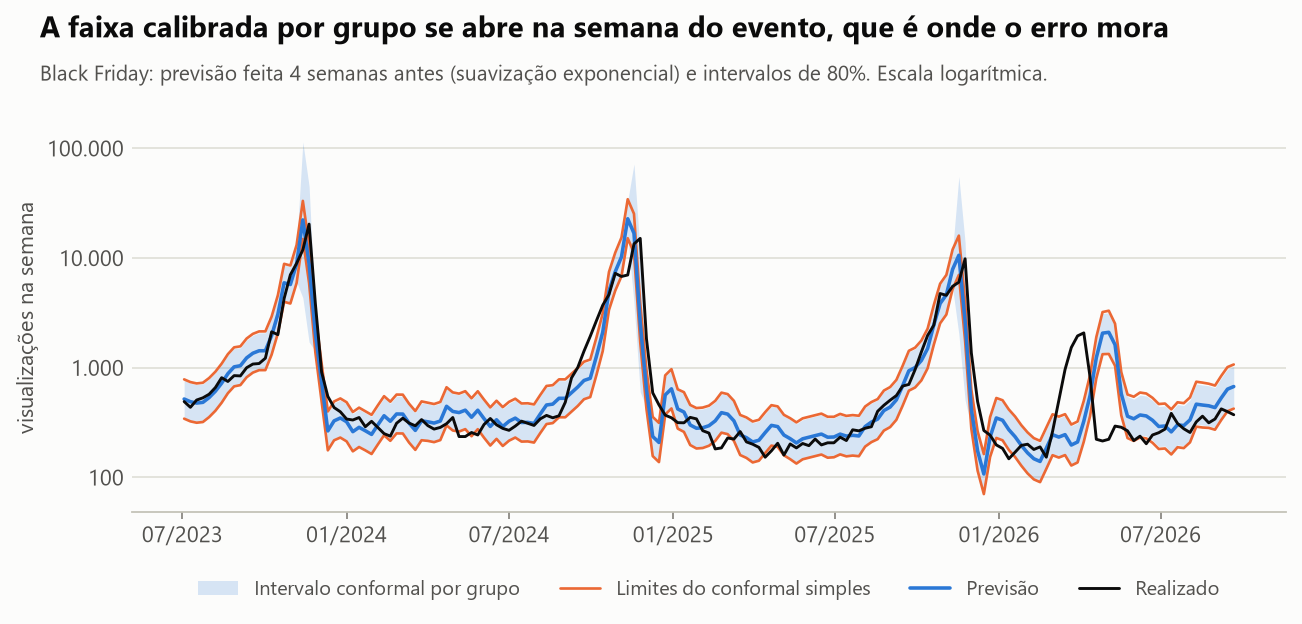

In [11]:
fig = graficos.exemplo_de_intervalos(r.exemplo, dados.rotulo(analise.ARTIGO_DE_EXEMPLO), analise.HORIZONTE_DE_EXEMPLO)
display(fig); plt.close(fig)

In [12]:
eventos_por_horizonte = r.cobertura_em_eventos.xs((0.80, "semana de evento"), level=("nivel", "recorte"))["cobertura"].unstack("horizonte")
eventos_por_horizonte.reindex(list(analise.METODOS)).rename(index=analise.METODOS).rename(columns={0: "todos"})

horizonte,todos,1,2,3,4,5,6,7,8
metodo,,,,,,,,,
Paramétrico do modelo,"0,401","0,382","0,382","0,391","0,391","0,391","0,422","0,435","0,417"
Conformal simples,"0,392","0,336","0,364","0,382","0,391","0,391","0,385","0,426","0,463"
Conformal adaptativo (ACI),"0,424","0,382","0,400","0,427","0,400","0,436","0,450","0,435","0,463"
Conformal por grupo,"0,823","0,809","0,800","0,845","0,827","0,845","0,835","0,824","0,796"


A falha não é questão de horizonte: a uma semana do evento a cobertura não é melhor do que a oito semanas.

## 5. Quando os erros mudam de tamanho

O conformal simples supõe que os erros de amanhã se parecem com os de ontem. Quando os erros crescem, ele fica para
trás até a calibração alcançar. O adaptativo corrige o nível a cada erro.

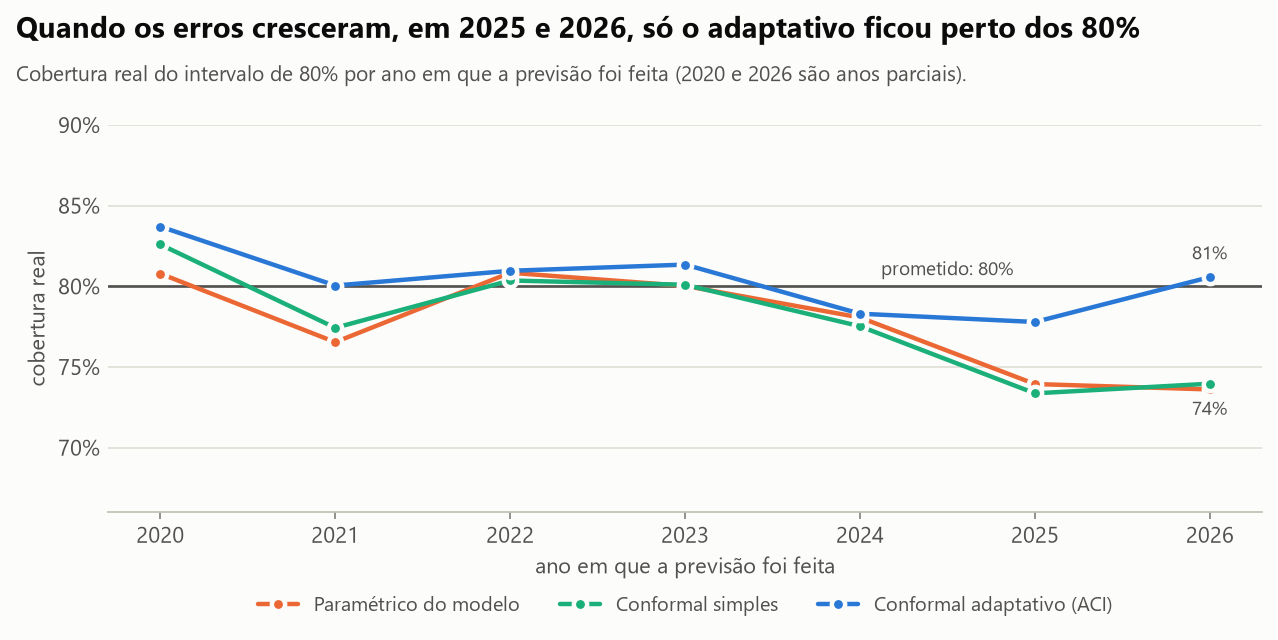

,Paramétrico do modelo,Conformal simples,Conformal adaptativo (ACI),Conformal por grupo,origens
ano,,,,,
2020,"0,808","0,826","0,837","0,831",27
2021,"0,765","0,774","0,800","0,771",52
2022,"0,808","0,804","0,810","0,802",52
2023,"0,800","0,801","0,813","0,806",52
2024,"0,781","0,775","0,783","0,774",53
2025,"0,739","0,734","0,778","0,727",52
2026,"0,736","0,740","0,806","0,731",35


In [13]:
fig = graficos.cobertura_por_ano(r.cobertura_por_ano)
display(fig); plt.close(fig)
r.cobertura_por_ano.rename(columns=analise.METODOS)

O passo de correção da ACI (gama = 0,02) foi fixado antes de olhar os resultados. A tabela abaixo mostra o que
aconteceria com outros valores: passo maior segura a cobertura com mais firmeza e produz mais intervalos infinitos.

In [14]:
r.sensibilidade_ao_gama

cobertura  cobertura_inf  cobertura_sup  fator_mediano  \
gama  nivel                                                           
0,005 0,800      0,791          0,760          0,813          1,699   
      0,950      0,949          0,935          0,958          2,978   
0,010 0,800      0,796          0,765          0,818          1,713   
      0,950      0,949          0,936          0,958          3,055   
0,020 0,800      0,801          0,771          0,822          1,732   
      0,950      0,950          0,939          0,958          3,206   
0,050 0,800      0,804          0,776          0,822          1,740   
      0,950      0,951          0,941          0,958          3,681   

             intervalos_infinitos  
gama  nivel                        
0,005 0,800                 0,000  
      0,950                 0,013  
0,010 0,800                 0,000  
      0,950                 0,042  
0,020 0,800                 0,009  
      0,950                 0,130  
0,050 0,800                 0,080  
      0,950                 0,307

## 6. O intervalo conformal em volta de cada previsor

O método conformal aceita qualquer previsão pontual. A cobertura geral fica perto do prometido em todos; o que muda
é a largura, que é o preço de prever pior. Na semana de evento, previsor melhor também significa faixa mais estreita.

In [15]:
r.conformal_por_modelo.reset_index().assign(metodo=lambda t: t["metodo"].map(analise.METODOS)).set_index(["nome", "metodo"]).drop(columns=["modelo"])

cobertura  cobertura_inf  \
nome                   metodo                                                 
Sazonal ingênua        Conformal adaptativo (ACI)      0,791          0,748   
                       Conformal por grupo             0,733          0,692   
Média móvel            Conformal adaptativo (ACI)      0,801          0,775   
                       Conformal por grupo             0,802          0,776   
Suavização exponencial Conformal adaptativo (ACI)      0,801          0,771   
                       Conformal por grupo             0,776          0,743   
Gradient boosting      Conformal adaptativo (ACI)      0,803          0,774   
                       Conformal por grupo             0,790          0,762   

                                                   cobertura_sup  \
nome                   metodo                                      
Sazonal ingênua        Conformal adaptativo (ACI)          0,822   
                       Conformal por grupo                 0,766   
Média móvel            Conformal adaptativo (ACI)          0,822   
                       Conformal por grupo                 0,823   
Suavização exponencial Conformal adaptativo (ACI)          0,822   
                       Conformal por grupo                 0,801   
Gradient boosting      Conformal adaptativo (ACI)          0,828   
                       Conformal por grupo                 0,816   

                                                   fator_mediano  \
nome                   metodo                                      
Sazonal ingênua        Conformal adaptativo (ACI)          1,841   
                       Conformal por grupo                 1,735   
Média móvel            Conformal adaptativo (ACI)          5,465   
                       Conformal por grupo                 3,384   
Suavização exponencial Conformal adaptativo (ACI)          1,732   
                       Conformal por grupo                 1,634   
Gradient boosting      Conformal adaptativo (ACI)          1,580   
                       Conformal por grupo                 1,552   

                                                   cobertura_evento  \
nome                   metodo                                         
Sazonal ingênua        Conformal adaptativo (ACI)             0,581   
                       Conformal por grupo                    0,802   
Média móvel            Conformal adaptativo (ACI)             0,240   
                       Conformal por grupo                    0,865   
Suavização exponencial Conformal adaptativo (ACI)             0,424   
                       Conformal por grupo                    0,823   
Gradient boosting      Conformal adaptativo (ACI)             0,609   
                       Conformal por grupo                    0,842   

                                                   cobertura_evento_inf  \
nome                   metodo                                             
Sazonal ingênua        Conformal adaptativo (ACI)                 0,490   
                       Conformal por grupo                        0,711   
Média móvel            Conformal adaptativo (ACI)                 0,170   
                       Conformal por grupo                        0,823   
Suavização exponencial Conformal adaptativo (ACI)                 0,334   
                       Conformal por grupo                        0,754   
Gradient boosting      Conformal adaptativo (ACI)                 0,529   
                       Conformal por grupo                        0,771   

                                                   cobertura_evento_sup  \
nome                   metodo                                             
Sazonal ingênua        Conformal adaptativo (ACI)                 0,665   
                       Conformal por grupo                        0,877   
Média móvel            Conformal adaptativo (ACI)                 0,315   
                       Conformal por grupo                   

## O que fica

- A previsão pontual melhora com calendário: o gradient boosting erra menos que a sazonal ingênua em todos os
  horizontes.
- No geral, o intervalo paramétrico de 95% cobre menos do que promete; os conformes entregam.
- Na semana da data comemorativa, nenhum intervalo de largura fixa entrega. Calibrar essas semanas à parte resolve a
  cobertura e mostra o tamanho real da incerteza no pico.
- Limites: são visualizações de página, não vendas; dez séries; a variante por grupo foi decidida depois de ver a
  falha; Imposto de renda e Enem não têm data calculável. O README detalha.